### iterativeimputer
### simpleimputer

# Missing values handeling

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import missingno as msno

In [3]:
df_air = pd.read_csv('air-quality.csv', parse_dates = ['Date'],index_col='Date')

In [4]:
df_air.head()

,Ozone,Solar.R,Wind,Temp
Date,,,,
1973-05-01,41.0,190.0,7.4,67
1973-05-02,36.0,118.0,8.0,72
1973-05-03,12.0,149.0,12.6,74
1973-05-04,18.0,313.0,11.5,62
1973-05-05,NaN,NaN,14.3,56


In [5]:
nullity_df = df_air.isnull().sum().to_frame(name = 'Missing Values')

In [6]:
nullity_df['%Missing'] = (df_air.isnull().mean()*100).round(1)

In [7]:
nullity_df

,Missing Values,%Missing
Ozone,37,24.2
Solar.R,7,4.6
Wind,0,0.0
Temp,0,0.0


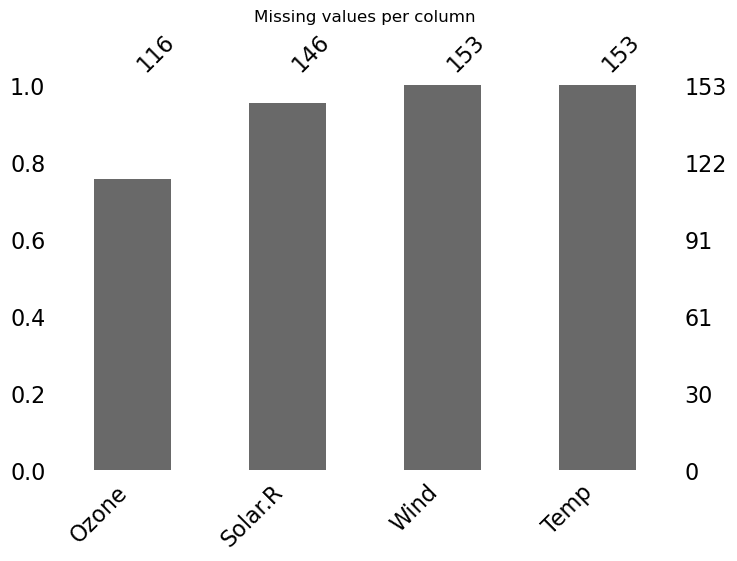

In [8]:
msno.bar(df_air, figsize=(8,5))
plt.title("Missing values per column")
plt.show()


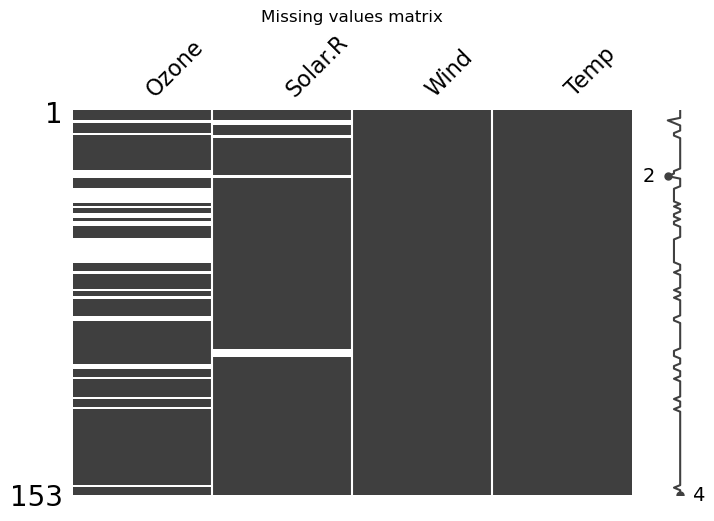

In [9]:
msno.matrix(df_air, figsize=(8,5))
plt.title("Missing values matrix")
plt.show()


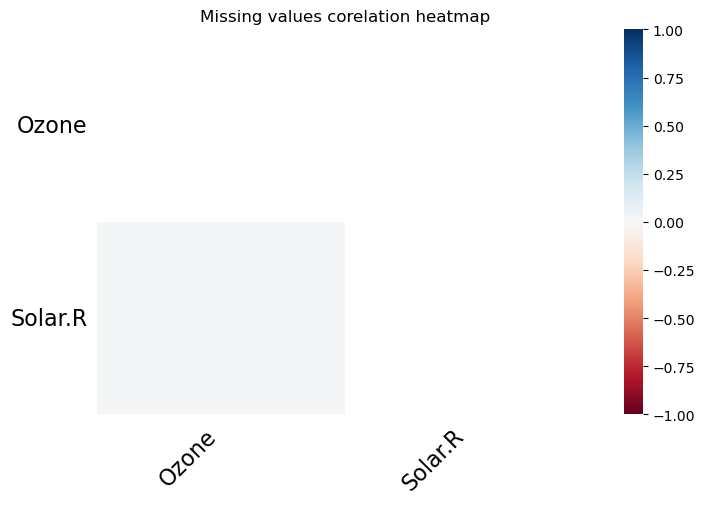

In [10]:
msno.heatmap(df_air, figsize=(8,5))
plt.title("Missing values corelation heatmap")
plt.show()

# Feature engineering

In [11]:
# each column is called a feature in data science
# All coulmns are know while one coulmn is predicted
# target is also called Label also
# Input feactures vs target features
# manipulation of input feachers 
# goal is to clean data so that our target is accurate as much as possible

In [12]:
import pandas as pd
from sklearn.datasets import load_wine

wine = load_wine()

df = pd.DataFrame(wine.data, columns=wine.feature_names)
df['target'] = wine.target
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [13]:
df.shape

(178, 14)

In [14]:
from sklearn.model_selection import train_test_split

X = df.drop('target', axis=1)
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [15]:
X_train.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
158,14.34,1.68,2.70,25.0,98.0,2.80,1.31,0.53,2.70,13.00,0.57,1.96,660.0
137,12.53,5.51,2.64,25.0,96.0,1.79,0.60,0.63,1.10,5.00,0.82,1.69,515.0
98,12.37,1.07,2.10,18.5,88.0,3.52,3.75,0.24,1.95,4.50,1.04,2.77,660.0
159,13.48,1.67,2.64,22.5,89.0,2.60,1.10,0.52,2.29,11.75,0.57,1.78,620.0
38,13.07,1.50,2.10,15.5,98.0,2.40,2.64,0.28,1.37,3.70,1.18,2.69,1020.0


In [16]:
y_train.head()

158    2
137    2
98     1
159    2
38     0
Name: target, dtype: int32

In [17]:
X_train.shape

(142, 13)

In [18]:
X_test.shape

(36, 13)

# Standardization and Normalization

In [19]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [20]:
X_train_scaled

array([[ 1.66529275, -0.60840587,  1.21896194, ..., -1.65632857,
        -0.87940904, -0.24860607],
       [-0.54952506,  2.7515415 ,  1.00331502, ..., -0.58463272,
        -1.25462095, -0.72992237],
       [-0.74531007, -1.14354109, -0.93750727, ...,  0.35845962,
         0.2462267 , -0.24860607],
       ...,
       [ 1.714239  , -0.44172441,  0.06884503, ...,  1.04434496,
         0.56585166,  2.69572196],
       [-0.35374006, -0.7399965 , -0.36244882, ...,  0.01551695,
        -0.74044166, -0.79631083],
       [-0.78201975,  0.06709269,  0.35637426, ..., -0.67036839,
         1.09392769, -0.98551793]])

In [21]:
from sklearn.preprocessing import Normalizer

normalizer = Normalizer()
X_train_norm = normalizer.fit_transform(X_train_scaled)
X_test_norm = normalizer.transform(X_test_scaled)

In [22]:
X_test_norm

array([[ 2.63761110e-01,  2.07855770e-01,  2.33447092e-01,
        -4.04832414e-01,  3.47525156e-01,  2.10894735e-01,
         3.35025851e-01, -5.05297077e-01,  2.91441323e-02,
         5.95279985e-03,  5.06071299e-03,  3.47710077e-01,
         1.19200344e-01],
       [ 4.91191475e-01,  4.76756543e-01,  9.27754625e-02,
        -5.43015047e-02,  2.35803321e-01,  2.87851443e-01,
         2.11149494e-01, -1.73566677e-01, -2.00751160e-01,
         2.56083918e-02, -1.20756162e-01,  3.34080689e-01,
         3.73574971e-01],
       [-1.86398560e-02,  1.18832604e-01,  3.78293458e-01,
         1.37632904e-01, -9.44611394e-02, -3.65828323e-01,
        -4.65874145e-01,  3.93271609e-01, -4.57844443e-01,
        -6.11417388e-02, -2.47953468e-01, -1.21971088e-01,
        -1.38961684e-01],
       [ 2.54128735e-01, -2.11938761e-01,  3.37126912e-01,
         2.43161043e-01,  1.05393907e-02,  3.09406249e-01,
         3.44910219e-01, -1.68837577e-01,  3.67098361e-01,
         7.64914225e-02,  2.76977384e

### Random forest classifier for identifying importent features which contribute most in predicting

In [23]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_scaled, y_train)

RandomForestClassifier(random_state=42)

In [24]:
from sklearn.feature_selection import SelectFromModel

selector = SelectFromModel(rf, threshold="median")
X_train_selected  = selector.transform(X_train_scaled)
X_test_selected = selector.transform(X_test_scaled)

In [25]:
X_train_scaled

array([[ 1.66529275, -0.60840587,  1.21896194, ..., -1.65632857,
        -0.87940904, -0.24860607],
       [-0.54952506,  2.7515415 ,  1.00331502, ..., -0.58463272,
        -1.25462095, -0.72992237],
       [-0.74531007, -1.14354109, -0.93750727, ...,  0.35845962,
         0.2462267 , -0.24860607],
       ...,
       [ 1.714239  , -0.44172441,  0.06884503, ...,  1.04434496,
         0.56585166,  2.69572196],
       [-0.35374006, -0.7399965 , -0.36244882, ...,  0.01551695,
        -0.74044166, -0.79631083],
       [-0.78201975,  0.06709269,  0.35637426, ..., -0.67036839,
         1.09392769, -0.98551793]])

In [26]:
features_bool = selector.get_support()
selected_features = X.columns[features_bool]

In [27]:
X_train[selected_features].head()

,alcohol,magnesium,flavanoids,color_intensity,hue,od280/od315_of_diluted_wines,proline
158,14.34,98.0,1.31,13.00,0.57,1.96,660.0
137,12.53,96.0,0.60,5.00,0.82,1.69,515.0
98,12.37,88.0,3.75,4.50,1.04,2.77,660.0
159,13.48,89.0,1.10,11.75,0.57,1.78,620.0
38,13.07,98.0,2.64,3.70,1.18,2.69,1020.0


# Outlier Detection/Analysis

## Histogram plot

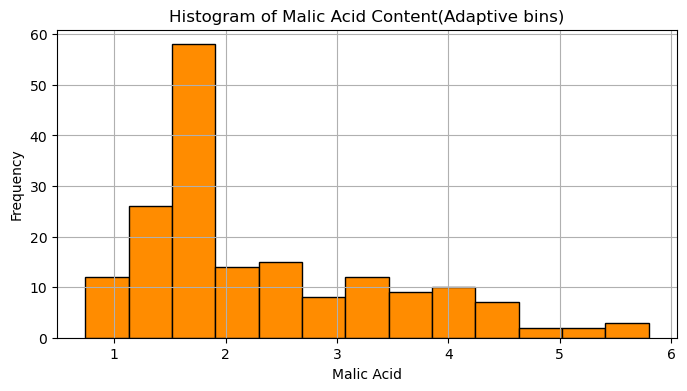

In [28]:
import matplotlib.pyplot

macid = df['malic_acid']
n_bins = int(np.sqrt(len(macid)))

plt.figure(figsize=(8,4))
plt.hist(macid, bins=n_bins, color= 'darkorange', edgecolor = 'black')
plt.title('Histogram of Malic Acid Content(Adaptive bins)')
plt.xlabel('Malic Acid')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

## scatter plot

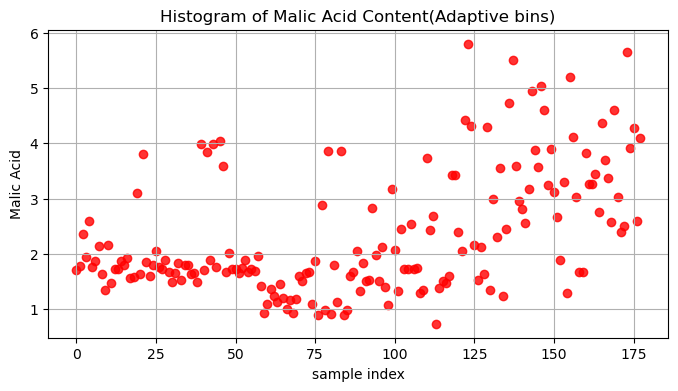

In [35]:
import matplotlib.pyplot

integers = range(len(macid))

plt.figure(figsize=(8,4))
plt.scatter(integers, macid, color= 'red', alpha = 0.8)
plt.title('Histogram of Malic Acid Content(Adaptive bins)')
plt.xlabel('sample index')
plt.ylabel('Malic Acid')
plt.grid(True)
plt.show()

### Z score for outliers
### 3 quartiles
### Boxplot
### Q2 is means

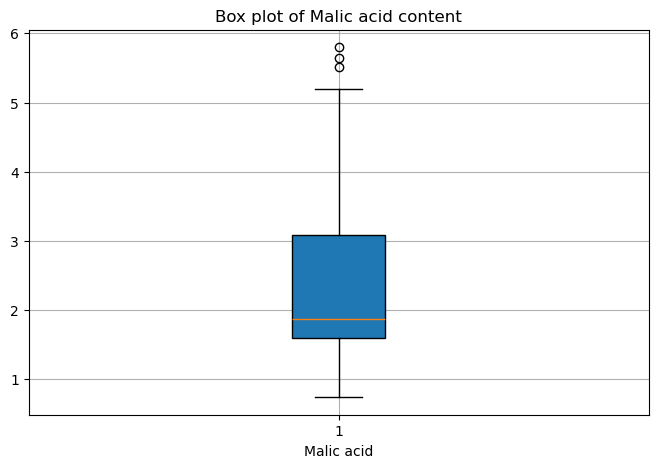

In [40]:
import matplotlib.pyplot as plt

# Plot boxplot
plt.figure(figsize=(8,5))
plt.boxplot(macid,patch_artist=True)
plt.title('Box plot of Malic acid content')
plt.xlabel('Malic acid')
plt.grid(True)
plt.show()